# LSRTM · elastic (Born, variable density)

`ElasticBorn` is the Born (single-scattering) equation of the first-order elastic equation
`Elastic`: a background velocity–stress field driven by the source through the smooth model
$(v_p, v_s, \rho)$, and a scattered field `svx, svz, ssxx, sszz, ssxz` driven by the perturbation
$(\delta v_p, \delta v_s, \delta\rho)$ acting on the background field (Li et al., 2019, eq. 5, here in
velocity–stress form):

$$\rho\,\partial_t \delta\mathbf v = \nabla\cdot\delta\boldsymbol\sigma - \delta\rho\,\partial_t\mathbf v_0,\qquad
\partial_t\delta\boldsymbol\sigma = \mathbf C:\boldsymbol\varepsilon(\delta\mathbf v) + \delta\mathbf C:\boldsymbol\varepsilon(\mathbf v_0).$$

The scattered step is the exact derivative of the `Elastic` step, so the scattered record is the
derivative of the `Elastic` record along the perturbation. The perturbations are absolute, in the
units of the background.

This notebook

1. builds a smooth layered background with one reflector and three separate anomalies, one per
   parameter;
2. models Born data and checks them against a finite difference of `Elastic` data;
3. images $(\delta v_p, \delta v_s, \delta\rho)$ by RTM and least-squares RTM on `impl='c'`;
4. takes the gradient of the background — the elastic reflection-waveform-inversion (RWI)
   gradient — on `impl='eager'`.

## 1. Model and survey

In [1]:
import sys, pathlib

_repo = pathlib.Path().resolve().parents[1]     # docs/notebooks/ -> repo root
if str(_repo / "src") not in sys.path:
    sys.path.insert(0, str(_repo / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations import Elastic, ElasticBorn
from sweep.propagator import BoundarySaving, Ckpt, PropTorch
from sweep.signal import ricker

torch.backends.cudnn.allow_tf32 = False         # eager convolutions in fp32 on Ampere and later
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


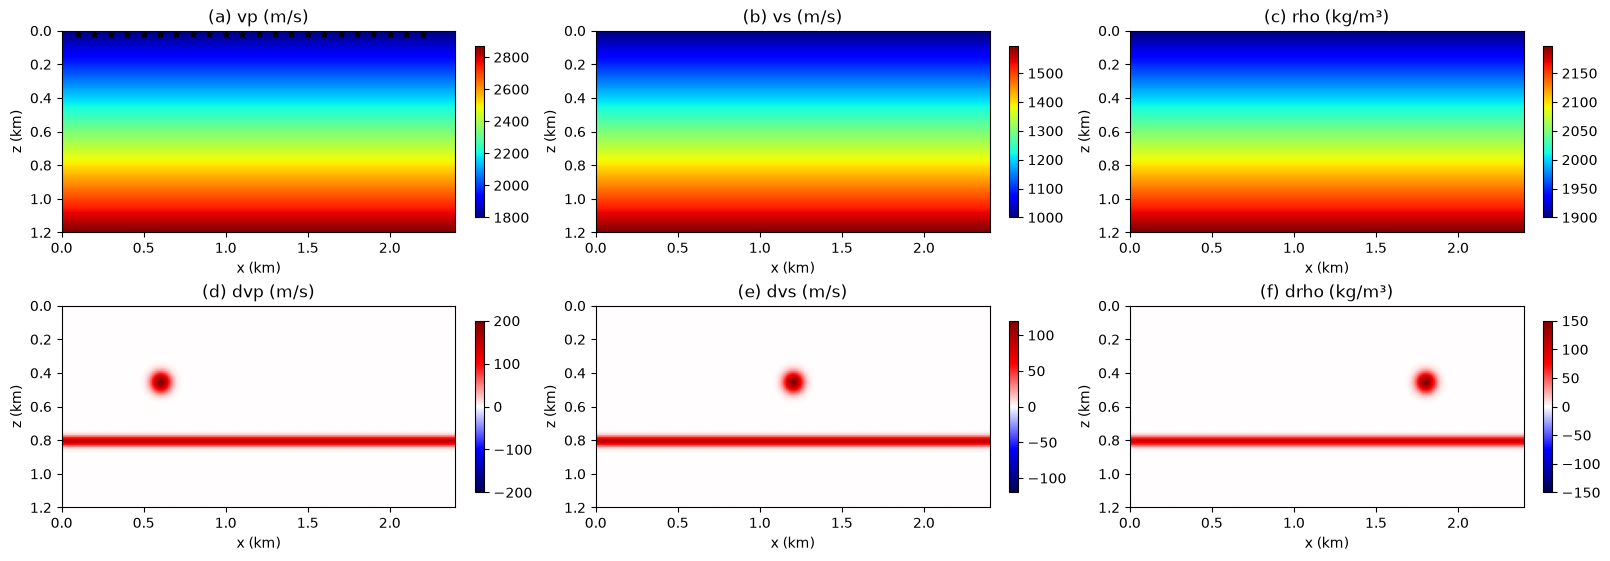

In [2]:
nz, nx, dh = 120, 240, 10.0                     # 1.2 km deep x 2.4 km, 10 m grid
z = np.arange(nz, dtype=np.float32)[:, None] * dh + np.zeros((1, nx), np.float32)
x = np.arange(nx, dtype=np.float32)[None, :] * dh + np.zeros((nz, 1), np.float32)

vp = (1800.0 + 0.9 * z).astype(np.float32)      # smooth background
vs = (vp / 1.8).astype(np.float32)
rho = (1900.0 + 0.25 * z).astype(np.float32)

def blob(z0, x0, r=40.0):
    return np.exp(-((z - z0) ** 2 + (x - x0) ** 2) / (2 * r ** 2))

def layer(z0, w=20.0):
    return np.exp(-(z - z0) ** 2 / (2 * w ** 2))

# one reflector felt by all three parameters, and one anomaly per parameter
dvp = (150 * layer(800) + 200 * blob(450, 600)).astype(np.float32)
dvs = (90 * layer(800) + 120 * blob(450, 1200)).astype(np.float32)
drho = (100 * layer(800) + 150 * blob(450, 1800)).astype(np.float32)

src_x = np.arange(10, nx - 10, 10)               # 22 shots every 100 m
nshots = len(src_x)
sources = np.stack([src_x, np.full(nshots, 2)], 1)                         # (x, z), z = 20 m
rec_x = np.arange(2, nx - 2, 2)                  # 118 receivers every 20 m
receivers = np.repeat(np.stack([rec_x, np.full_like(rec_x, 2)], 1)[None], nshots, 0)

dt, nt, fm, delay = 1e-3, 1500, 8.0, 0.15        # 1.5 s, 8 Hz Ricker
wavelet = ricker(np.arange(nt, dtype=np.float32) * dt - delay, f=fm)
order, abcn, batch = 8, 40, 8   # vs >= 1000 m/s: ~5 points per shortest S wavelength at 10 m

extent = [0, nx * dh / 1000, nz * dh / 1000, 0]
fig, ax = plt.subplots(2, 3, figsize=(16, 5.5), constrained_layout=True)
for a, (m, title) in zip(ax[0], ((vp, "(a) vp (m/s)"), (vs, "(b) vs (m/s)"), (rho, "(c) rho (kg/m³)"))):
    fig.colorbar(a.imshow(m, cmap="jet", extent=extent, aspect="auto"), ax=a, shrink=0.85)
    a.set_title(title)
for a, (m, title) in zip(ax[1], ((dvp, "(d) dvp (m/s)"), (dvs, "(e) dvs (m/s)"), (drho, "(f) drho (kg/m³)"))):
    c = np.abs(m).max()
    fig.colorbar(a.imshow(m, cmap="seismic", vmin=-c, vmax=c, extent=extent, aspect="auto"), ax=a, shrink=0.85)
    a.set_title(title)
ax[0, 0].plot(sources[:, 0] * dh / 1000, sources[:, 1] * dh / 1000, "k*", ms=5)
for a in ax.ravel():
    a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
plt.show()

## 2. Born data

The observed data are the Born data of the true perturbation: the scattered velocities `svx`,
`svz` of every shot, with a free surface on top. `impl='c'` steps the background and the scattered
field together; boundary saving keeps only the background's boundary strips for the backward.

Born data (shots, nt, receivers, [svx, svz]): (22, 1500, 118, 2)


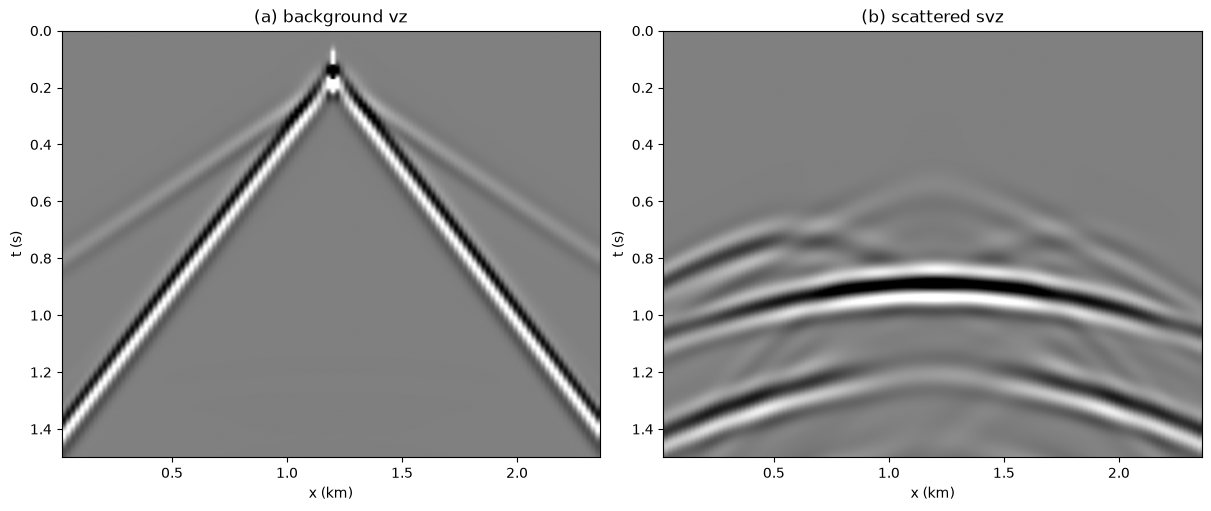

In [3]:
T = lambda a: torch.tensor(a, device=device)
bg = [T(vp), T(vs), T(rho)]
w = T(wavelet)


def born_solver(impl="c", memory=None, receiver_type=("svx", "svz")):
    eq = ElasticBorn(spatial_order=order, device=device)
    return PropTorch(eq, shape=(nz, nx), dh=dh, dt=dt, nt=nt, abcn=abcn, free_surface=True,
                     impl=impl, memory=memory or BoundarySaving(),
                     source_type=["sxx", "szz"], receiver_type=list(receiver_type))


solver = born_solver()


def born(pert, background=bg):
    # Born data of the perturbation [dvp, dvs, drho], every shot, (shots, nt, receivers, 2)
    with torch.no_grad():
        return torch.cat([solver(w, sources[i:i + batch], receivers[i:i + batch],
                                 models=list(background) + list(pert))
                          for i in range(0, nshots, batch)])


pert_true = [T(dvp), T(dvs), T(drho)]
d_obs = born(pert_true)
# Born data are linear in the source: scale the source so the data peak at 1 (a unit stress
# source gives velocities near 1e-8, whose products underflow fp32 in the steps below)
scale = 1.0 / float(d_obs.abs().max())
w, d_obs = w * scale, d_obs * scale
print("Born data (shots, nt, receivers, [svx, svz]):", tuple(d_obs.shape))

k = nshots // 2                                  # the middle shot, background and scattered
with torch.no_grad():
    rec = born_solver(receiver_type=("vz", "svz"))(w, sources[k:k + 1], receivers[k:k + 1],
                                                   models=bg + pert_true)[0].cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for a, j, title in ((ax[0], 0, "(a) background vz"), (ax[1], 1, "(b) scattered svz")):
    c = np.percentile(np.abs(rec[..., j]), 99)
    a.imshow(rec[..., j], cmap="gray", vmin=-c, vmax=c, aspect="auto",
             extent=[rec_x[0] * dh / 1000, rec_x[-1] * dh / 1000, nt * dt, 0])
    a.set_title(title); a.set_xlabel("x (km)"); a.set_ylabel("t (s)")
plt.show()

The background record holds the waves of the smooth model only: the direct P wave (the weak, fast
event) and the stronger, slower Rayleigh wave along the free surface. The scattered record holds
what the perturbation sends back: the P reflection of the layer at 0.8 km (apex near 0.9 s), later
reflections of the same layer that travel part of the way as S waves, and the diffractions of the
three anomalies above them.

## 3. The scattered record is a derivative

`Elastic` records at $m \pm \epsilon\,\delta m$, differenced and Richardson-extrapolated, against
the Born record of the same shot.

max |Born - FD| / max |FD| = 7.6e-05


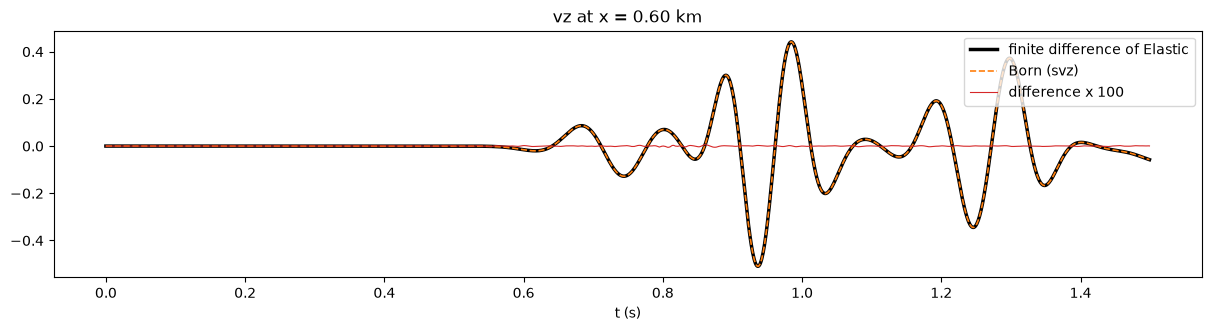

In [4]:
elastic = PropTorch(Elastic(spatial_order=order, device=device), shape=(nz, nx), dh=dh, dt=dt, nt=nt,
                    abcn=abcn, free_surface=True, impl="c", receiver_type=["vx", "vz"])


def elastic_record(eps):
    with torch.no_grad():
        return elastic(w, sources[k:k + 1], receivers[k:k + 1],
                       models=[b + eps * p for b, p in zip(bg, pert_true)])


central = lambda eps: (elastic_record(eps) - elastic_record(-eps)) / (2 * eps)
fd = ((4 * central(0.25) - central(0.5)) / 3)[0].cpu().numpy()      # error O(eps^4)
sc = d_obs[k].cpu().numpy()
print(f"max |Born - FD| / max |FD| = {np.abs(sc - fd).max() / np.abs(fd).max():.1e}")

r = len(rec_x) // 4
t = np.arange(nt) * dt
fig, ax = plt.subplots(figsize=(12, 3.2), constrained_layout=True)
ax.plot(t, fd[:, r, 1], "k", lw=2.5, label="finite difference of Elastic")
ax.plot(t, sc[:, r, 1], "C1--", lw=1.2, label="Born (svz)")
ax.plot(t, 100 * (sc[:, r, 1] - fd[:, r, 1]), "C3", lw=0.8, label="difference x 100")
ax.set_xlabel("t (s)"); ax.set_title(f"vz at x = {rec_x[r] * dh / 1000:.2f} km")
ax.legend(loc="upper right")
plt.show()

## 4. RTM: the gradient at $\delta m = 0$

The negative gradient of $J = \tfrac12\lVert d(\delta m) - d_{\rm obs}\rVert^2$ at $\delta m = 0$ is
the elastic RTM image of the data, one image per parameter. The top 10 rows (100 m), next to the
sources and receivers, are left out.

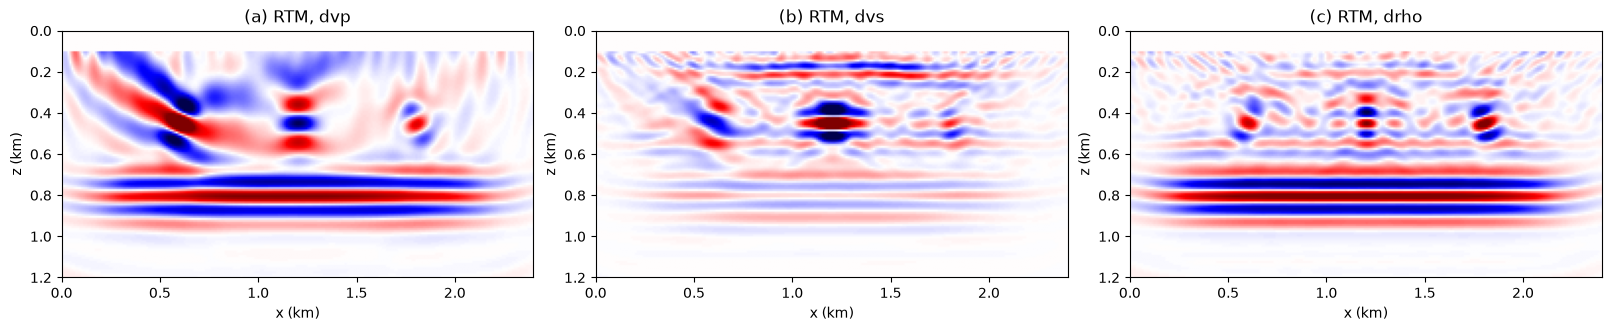

In [5]:
mask = torch.ones(nz, nx, device=device)
mask[:10] = 0


def misfit_grad(pert):
    # 0.5 |d(pert) - d_obs|^2 and its (dvp, dvs, drho) gradients, summed over the shots
    J, g = 0.0, [torch.zeros(nz, nx, device=device) for _ in range(3)]
    for i in range(0, nshots, batch):
        m = [p.detach().clone().requires_grad_(True) for p in pert]
        d = solver(w, sources[i:i + batch], receivers[i:i + batch], models=bg + m)
        loss = 0.5 * (d - d_obs[i:i + batch]).pow(2).sum()
        loss.backward()
        J += loss.item()
        g = [a + b.grad for a, b in zip(g, m)]
    return J, [a * mask for a in g]


zero = [torch.zeros(nz, nx, device=device) for _ in range(3)]
J0, g0 = misfit_grad(zero)
rtm = [-a.cpu().numpy() for a in g0]

names = ["dvp", "dvs", "drho"]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
for a, img, name, letter in zip(ax, rtm, names, "abc"):
    c = np.percentile(np.abs(img), 99.5)
    a.imshow(img, cmap="seismic", vmin=-c, vmax=c, extent=extent, aspect="auto")
    a.set_title(f"({letter}) RTM, {name}"); a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
plt.show()

Each RTM image holds the reflector and all three anomalies: the image of one parameter also
collects the scattering of the others. The $v_s$ anomaly (centre) is bright in all three images, the
$\rho$ image shows the three anomalies at similar strength, and the $v_p$ image carries a
low-wavenumber swing on the left above 0.6 km. RTM alone does not tell the parameters apart.

## 5. Least-squares RTM

LSRTM minimises $J$ over the three perturbations together. The Born map is linear in $\delta m$, so
$J$ is quadratic and conjugate gradients with the exact step $\alpha = -\langle g, p\rangle /
\lVert L p\rVert^2$ converge quickly; $L p$ is the Born data of the search direction.

In [6]:
def dot(a, b):
    return sum(float((x * y).sum()) for x, y in zip(a, b))


def lsrtm(niter=30):
    pert = [torch.zeros(nz, nx, device=device) for _ in range(3)]
    p = g_old = None
    history = []
    for it in range(niter):
        J, g = misfit_grad(pert)
        history.append(J)
        if p is None:
            p = [-a for a in g]
        else:
            beta = max(0.0, dot(g, [a - b for a, b in zip(g, g_old)]) / dot(g_old, g_old))
            p = [-a + beta * b for a, b in zip(g, p)]
        Lp = born(p)
        alpha = -dot(g, p) / float((Lp * Lp).sum())
        pert, g_old = [a + alpha * b for a, b in zip(pert, p)], g
    history.append(0.5 * float((born(pert) - d_obs).pow(2).sum()))
    return [a.cpu().numpy() for a in pert], np.array(history)


inverted, history = lsrtm()
print(f"data misfit after {len(history) - 1} iterations: {history[-1] / history[0]:.4f} of the start")

data misfit after 30 iterations: 0.0387 of the start


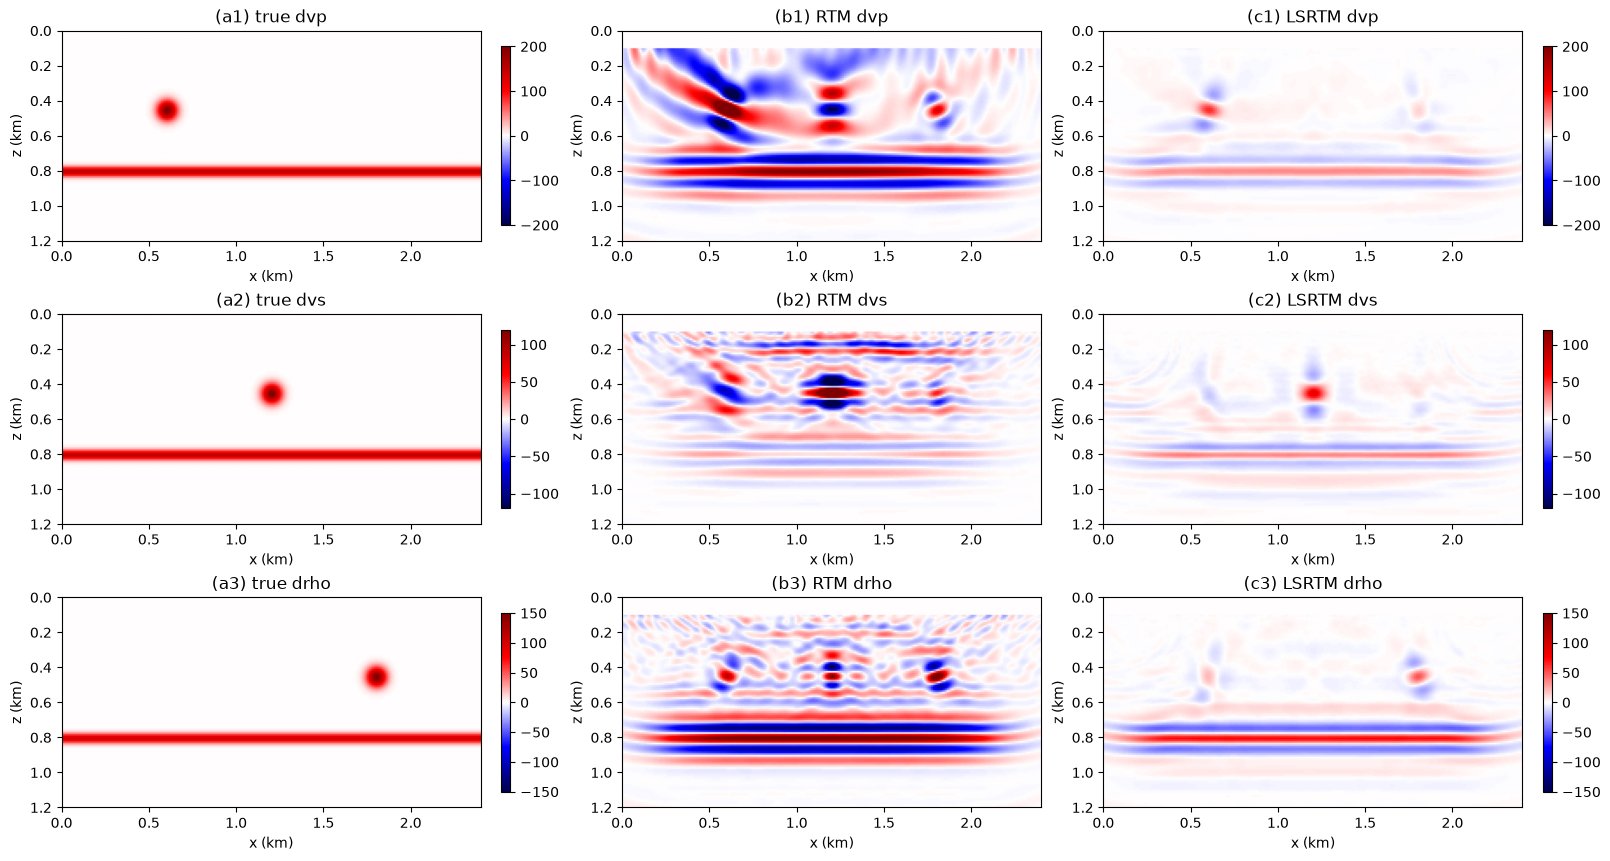

true -> LSRTM at the anomaly centres and on the reflector (z, x in m):
  dvp    dvp   200 ->    84 | dvs     0 ->    -0 | drho     0 ->    17 | reflector   150 ->    46
  dvs    dvp     0 ->   -12 | dvs   120 ->    72 | drho     0 ->     7 | reflector    90 ->    27
  drho   dvp     0 ->    20 | dvs     0 ->     2 | drho   150 ->    51 | reflector   100 ->    73


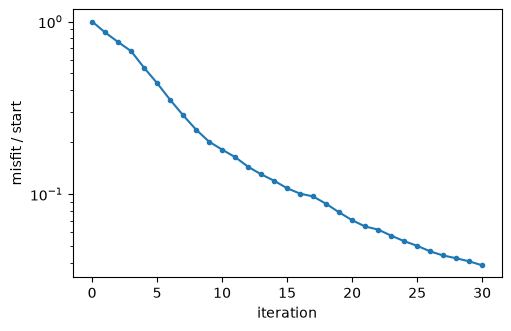

In [7]:
true = [dvp, dvs, drho]
fig, ax = plt.subplots(3, 3, figsize=(16, 8.5), constrained_layout=True)
for row, name in enumerate(names):
    for col, (img, label) in enumerate(((true[row], "true"), (rtm[row], "RTM"), (inverted[row], "LSRTM"))):
        a = ax[row, col]
        c = np.abs(true[row]).max() if col != 1 else np.percentile(np.abs(img), 99.5)
        im = a.imshow(img, cmap="seismic", vmin=-c, vmax=c, extent=extent, aspect="auto")
        a.set_title(f"({'abc'[col]}{row + 1}) {label} {name}")
        a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
        if col != 1:
            fig.colorbar(im, ax=a, shrink=0.85)
plt.show()

centres = {"dvp": (450, 600), "dvs": (450, 1200), "drho": (450, 1800), "reflector": (800, 1200)}
print("true -> LSRTM at the anomaly centres and on the reflector (z, x in m):")
for row, name in enumerate(names):
    cells = []
    for where, (zc, xc) in centres.items():
        iz, ix = int(zc / dh), int(xc / dh)
        cells.append(f"{where} {true[row][iz, ix]:5.0f} -> {inverted[row][iz, ix]:5.0f}")
    print(f"  {name:5s}  " + " | ".join(cells))

fig, ax = plt.subplots(figsize=(5, 3.2), constrained_layout=True)
ax.semilogy(history / history[0], "o-", ms=3)
ax.set_xlabel("iteration"); ax.set_ylabel("misfit / start")
plt.show()

Least squares moves each anomaly into its own parameter. $\delta v_s$ is the cleanest; the cross-talk
that remains is between $v_p$ and $\rho$, whose scattering is alike at the short offsets of most of
the data: a trace of the $v_p$ anomaly (left) in $\delta\rho$ and of the density anomaly (right) in
$\delta v_p$. The reflector comes back as a band-limited copy of the layer with side lobes (no
frequencies below about 2 Hz in the data). After 30 iterations the amplitudes are still below the
true ones (the values above).

## 6. The background gradient (elastic RWI)

Reflection waveform inversion updates the smooth background from the reflections the perturbation
predicts. Its gradient is the derivative of the same misfit with respect to $(v_p, v_s, \rho)$. The
compiled backward returns the perturbation gradients only, so this one runs on `impl='eager'`
(autograd), here with chunked checkpointing. The background below is 5 % too slow in $v_p$ and $v_s$;
to isolate the background gradient the perturbation is the true one (in RWI it comes from the
LSRTM above, alternated with the background updates).

sweep: compiling the eager time step with torch.compile; the first forward/backward pass takes longer (seconds to a few minutes, once per grid size, cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


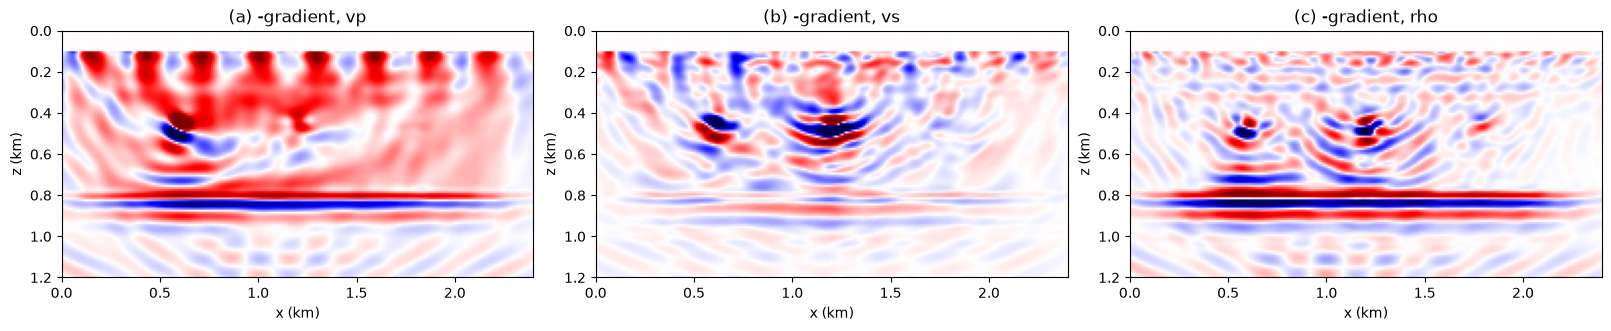

In [8]:
eager = born_solver(impl="eager", memory=Ckpt(mode="chunk", chunks=15))
bg_slow = [T(0.95 * vp), T(0.95 * vs), T(rho)]
rwi_shots = range(0, nshots, 3)                 # every third shot, three per call
m = [b.clone().requires_grad_(True) for b in bg_slow]
for i in range(0, len(rwi_shots), 3):
    sel = list(rwi_shots[i:i + 3])
    d = eager(w, sources[sel], receivers[sel], models=m + pert_true)
    (0.5 * (d - d_obs[sel]).pow(2).sum()).backward()

fig, ax = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
for a, mm, name, letter in zip(ax, m, ("vp", "vs", "rho"), "abc"):
    img = -(mm.grad * mask).cpu().numpy()
    c = np.percentile(np.abs(img), 99.5)
    a.imshow(img, cmap="seismic", vmin=-c, vmax=c, extent=extent, aspect="auto")
    a.set_title(f"({letter}) -gradient, {name}"); a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
plt.show()

The negative $v_p$ gradient is a broad positive update above the reflector, on the paths between
the shots and the reflector: the background is too slow and the gradient asks for a faster one
everywhere the reflections travel. Next to the surface it carries the footprint of each shot, and at
the reflector and the anomalies it also carries the sharp image-point terms. The $v_s$ and $\rho$
gradients are concentrated at the anomalies and the reflector. Li et al. (2019) take the
background update from the far offsets, where the reflection paths are long; an RWI loop would also
smooth the gradient before using it.

## 7. Notes

- **What each backend returns.** `impl='c'` returns the $(\delta v_p, \delta v_s, \delta\rho)$
  gradients in every memory mode (`Full`, `BoundarySaving`, `Ckpt`); the gradients of the background
  and of the wavelet raise `NotImplementedError` there. `impl='eager'` returns all of them.
- **Fields.** Sources go on the background (`sxx`, `szz`, `vx`, `vz`); receivers on either field —
  the scattered ones (`svx` … `ssxz`) by default, the background ones (`vx` … `sxz`) next to them.
- **Exactness.** The scattered step is the derivative of the `Elastic` step, CPML, free surface and
  topography included, so a Born record equals the derivative of the corresponding `Elastic`
  record (section 3).

## Reference

Li, Y., Guo, Q., Li, Z., & Alkhalifah, T. (2019). Elastic reflection waveform inversion with
variable density. *Geophysics, 84*(4), R553–R567.
[doi:10.1190/geo2017-0722.1](https://doi.org/10.1190/geo2017-0722.1) — the Born equation of the
elastic wave equation with $\delta v_p$, $\delta v_s$, $\delta\rho$ (their eq. 5) that `ElasticBorn`
implements in velocity–stress form, and the RWI gradients of section 6.